# Titanic — Common EDA, preprocessing and feature contract

This notebook is the single source of truth for the four model notebooks. It audits the raw data, performs EDA, learns preprocessing rules from Kaggle train only, creates one stratified hold-out split, and exports reusable artifacts. `RANDOM_STATE=42`; primary metric is accuracy; model notebooks must use `StratifiedKFold(10, shuffle=True, random_state=42)`.

In [1]:
from pathlib import Path
import json, platform, sys, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'PROJECT_PLAN.md').exists()), None)
assert ROOT is not None, 'Run from the repository or its notebooks directory.'
DATA_DIR = ROOT / 'input' / 'titanic'
ARTIFACT_DIR = ROOT / 'artifacts' / 'common'
FIGURE_DIR = ROOT / 'reports' / 'figures' / 'common'
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
versions = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__, 'seaborn': sns.__version__, 'scikit_learn': sklearn.__version__}
print(json.dumps(versions, indent=2))
print('Project root:', ROOT)

{
  "python": "3.14.7",
  "numpy": "2.5.4",
  "pandas": "3.1.0",
  "matplotlib": "3.11.2",
  "seaborn": "0.13.2",
  "scikit_learn": "1.9.1"
}
Project root: C:\Users\MSI\Desktop\MyProducts\My Project\AIL\Mini_Capstone


## Load and audit raw data

The audit covers shape, schema, duplicate rows, identifier uniqueness, missingness, target balance, and plausible range/IQR checks. `PassengerId` is retained only for row identity and submission output.

In [2]:
train_raw = pd.read_csv(DATA_DIR / 'train.csv')
test_raw = pd.read_csv(DATA_DIR / 'test.csv')
assert 'Survived' in train_raw and 'Survived' not in test_raw
print('Shapes:', {'train': train_raw.shape, 'test': test_raw.shape})
display(train_raw.head(), train_raw.tail(), train_raw.dtypes.rename('dtype').to_frame())
audit = pd.DataFrame({
    'duplicate_rows': [train_raw.duplicated().sum(), test_raw.duplicated().sum()],
    'unique_passenger_id': [train_raw.PassengerId.is_unique, test_raw.PassengerId.is_unique],
}, index=['train', 'test'])
display(audit)
for label, frame in [('train', train_raw), ('test', test_raw)]:
    missing = pd.DataFrame({'missing_count': frame.isna().sum(), 'missing_rate': frame.isna().mean()}).query('missing_count > 0')
    print(f'\n{label} missing values'); display(missing)
target_balance = train_raw.Survived.value_counts().sort_index().to_frame('count')
target_balance['rate'] = train_raw.Survived.value_counts(normalize=True).sort_index()
display(target_balance)
range_rules = {'Age': (0, 100), 'Fare': (0, np.inf), 'SibSp': (0, np.inf), 'Parch': (0, np.inf), 'Pclass': (1, 3)}
range_audit = []
for col, (low, high) in range_rules.items():
    s = train_raw[col].dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    range_audit.append({'feature': col, 'min': s.min(), 'max': s.max(), 'outside_plausible_range': int(((s < low) | (s > high)).sum()), 'iqr_outliers': int(((s < q1-1.5*iqr) | (s > q3+1.5*iqr)).sum())})
display(pd.DataFrame(range_audit))
assert train_raw.PassengerId.is_unique and test_raw.PassengerId.is_unique
assert not train_raw.duplicated().any() and not test_raw.duplicated().any()

Shapes: {'train': (891, 12), 'test': (418, 11)}


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


,dtype
PassengerId,int64
Survived,int64
Pclass,int64
Name,str
Sex,str
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64


,duplicate_rows,unique_passenger_id
train,0,True
test,0,True



train missing values


,missing_count,missing_rate
Age,177,0.198653
Cabin,687,0.771044
Embarked,2,0.002245



test missing values


,missing_count,missing_rate
Age,86,0.205742
Fare,1,0.002392
Cabin,327,0.782297


,count,rate
Survived,,
0,549,0.616162
1,342,0.383838


,feature,min,max,outside_plausible_range,iqr_outliers
0,Age,0.42,80.0000,0,11
1,Fare,0.00,512.3292,0,116
2,SibSp,0.00,8.0000,0,46
3,Parch,0.00,6.0000,0,213
4,Pclass,1.00,3.0000,0,0


## Univariate EDA

The target has more non-survivors than survivors, so stratification is required. Age is concentrated among young adults; Fare is strongly right-skewed with legitimate high-price outliers. SibSp and Parch are zero-heavy. Sex, passenger class, and embarkation port are imbalanced categories, with third class and Southampton most common.

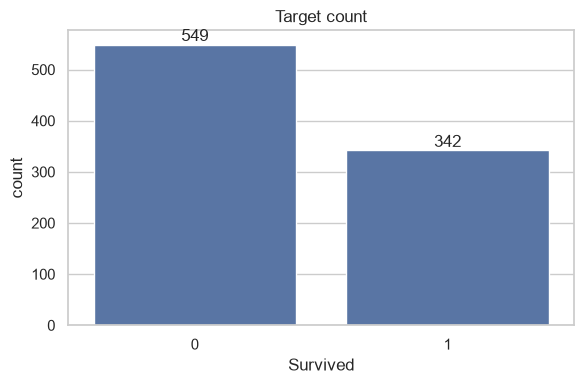

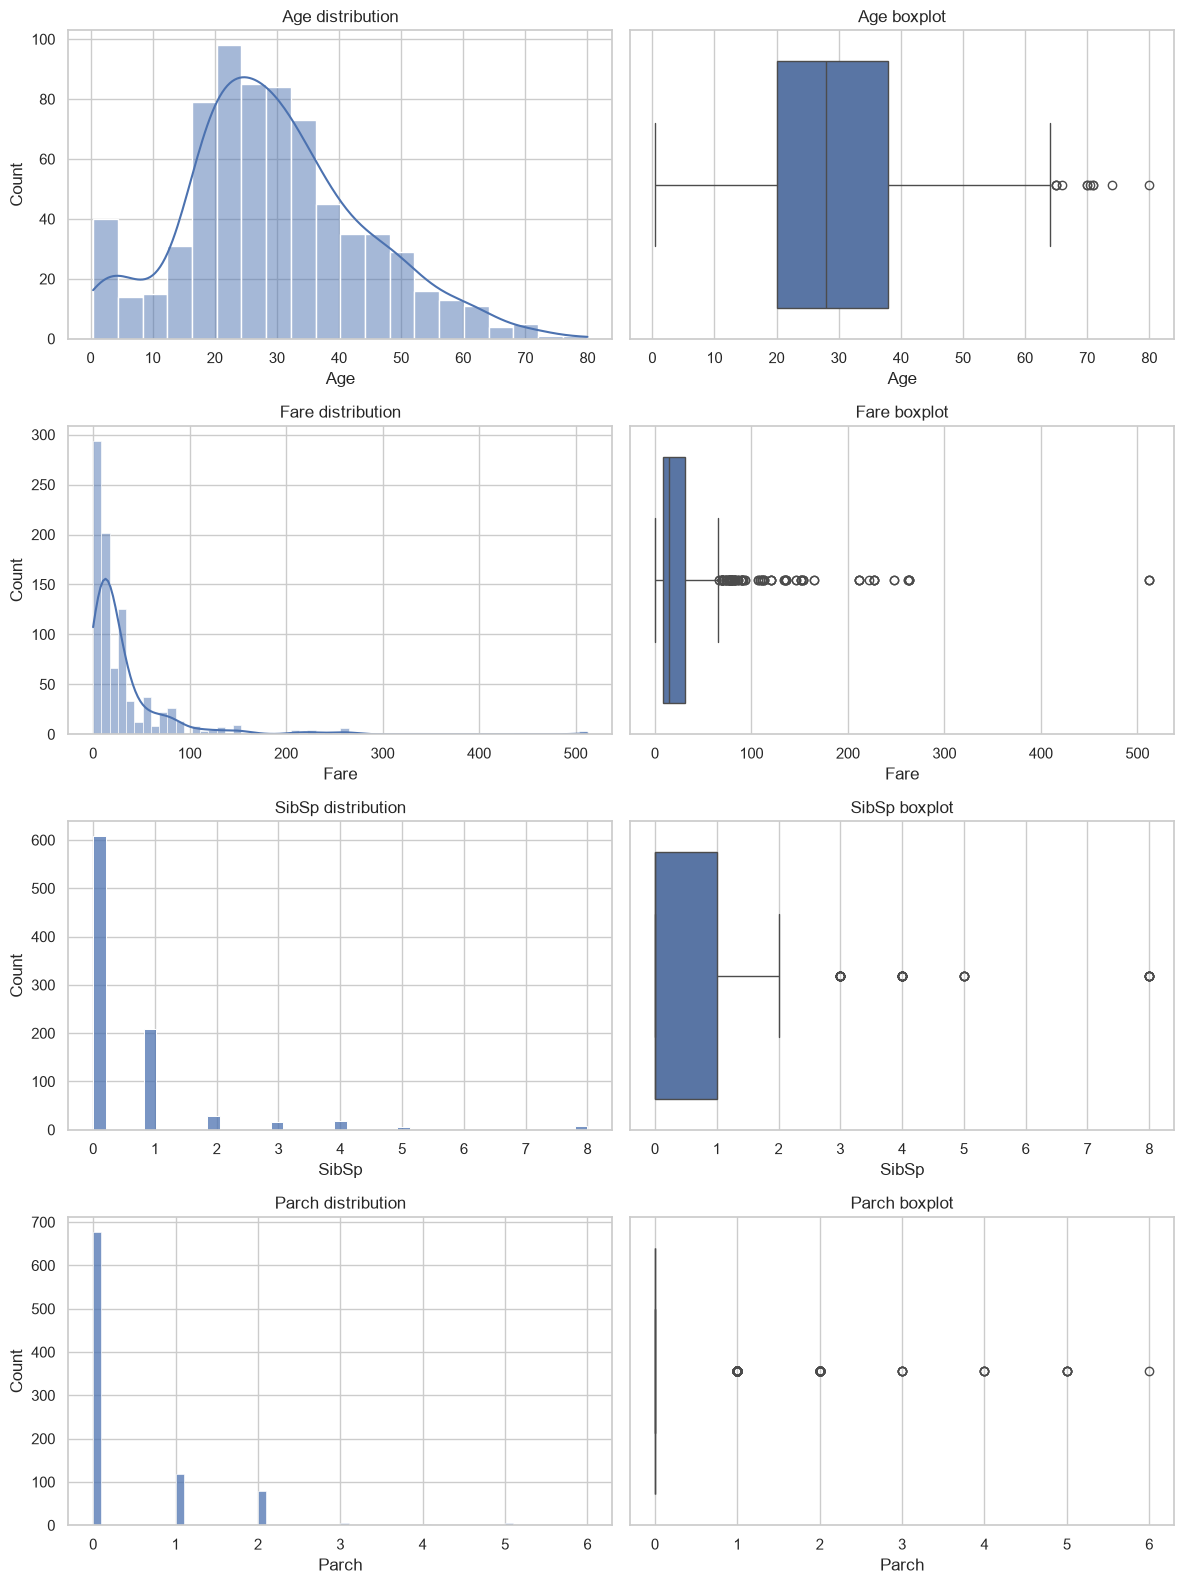

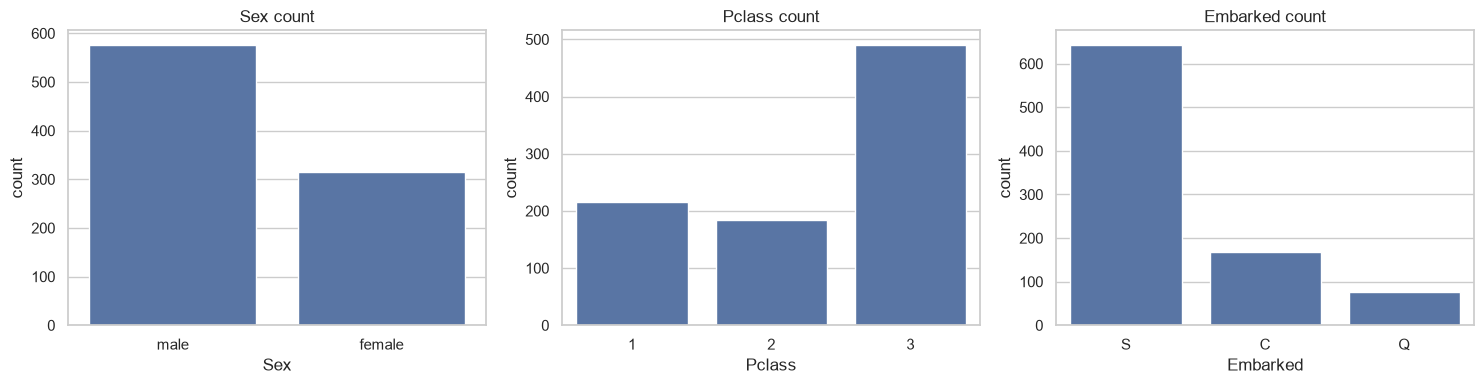

In [3]:
fig, ax = plt.subplots(figsize=(6,4)); sns.countplot(data=train_raw, x='Survived', ax=ax); ax.set_title('Target count');
for container in ax.containers: ax.bar_label(container)
fig.tight_layout(); fig.savefig(FIGURE_DIR / '01_target_balance.png', dpi=150); plt.show()
fig, axes = plt.subplots(4, 2, figsize=(12,16))
for row, col in enumerate(['Age','Fare','SibSp','Parch']):
    sns.histplot(train_raw[col], kde=(col in ['Age','Fare']), ax=axes[row,0]); axes[row,0].set_title(f'{col} distribution')
    sns.boxplot(x=train_raw[col], ax=axes[row,1]); axes[row,1].set_title(f'{col} boxplot')
fig.tight_layout(); fig.savefig(FIGURE_DIR / '02_numeric_univariate.png', dpi=150); plt.show()
fig, axes = plt.subplots(1,3,figsize=(15,4))
for ax, col in zip(axes, ['Sex','Pclass','Embarked']): sns.countplot(data=train_raw, x=col, ax=ax); ax.set_title(f'{col} count')
fig.tight_layout(); fig.savefig(FIGURE_DIR / '03_categorical_univariate.png', dpi=150); plt.show()

## Bivariate and multivariate EDA

Survival varies most visibly by sex and class; embarked-port differences partly overlap with class composition. Very large family counts have few observations and unstable rates. Survivors tend toward lower ages and higher fares. The Sex × Pclass view shows that the female advantage exists across classes but is not uniform; Age × Pclass shows especially poor outcomes for many third-class adults. These are associations, not causal effects.

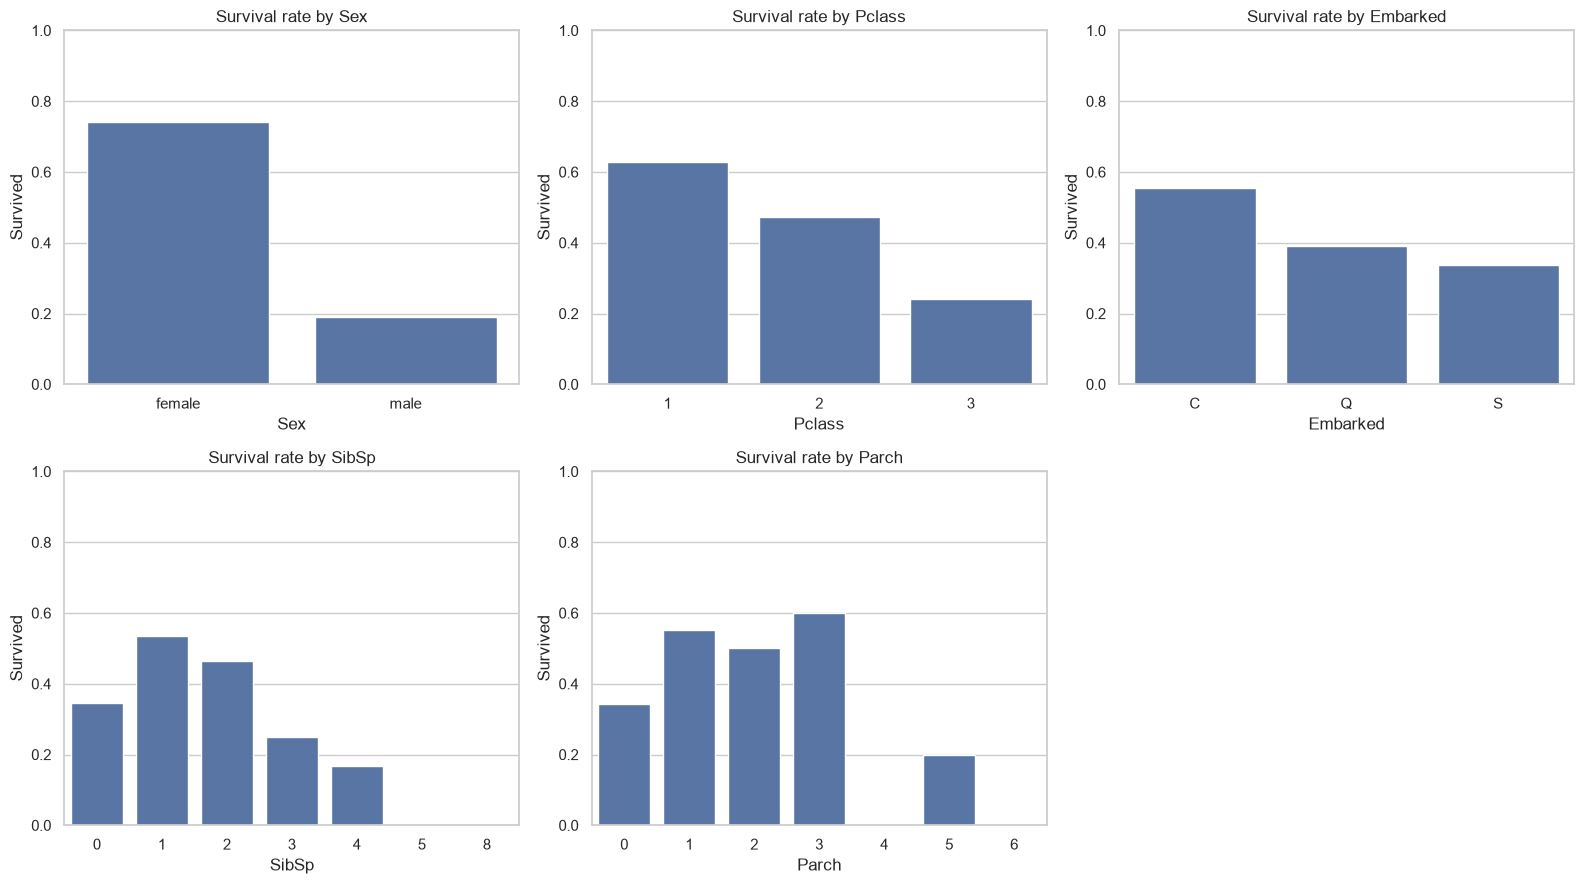

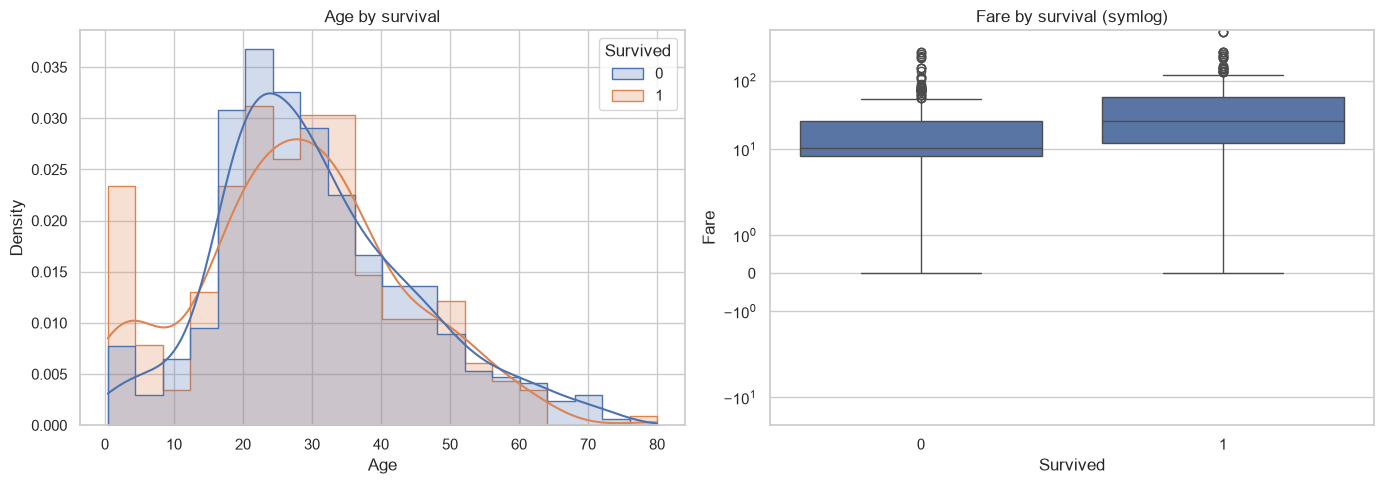

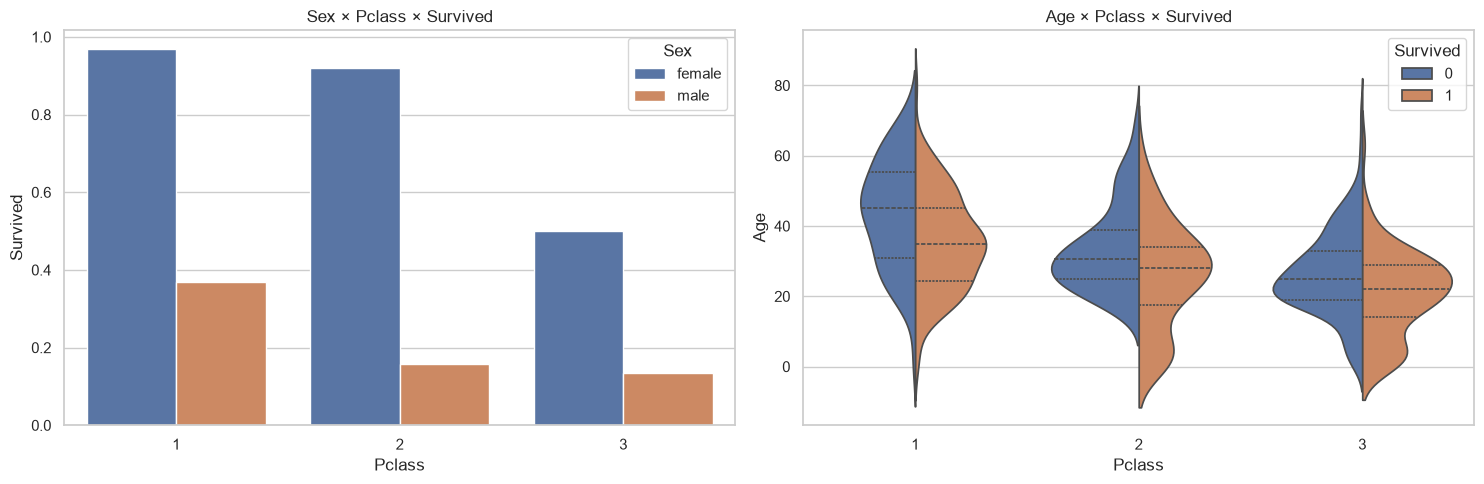

In [4]:
fig, axes = plt.subplots(2,3,figsize=(16,9))
for ax, col in zip(axes.flat, ['Sex','Pclass','Embarked','SibSp','Parch']):
    rates = train_raw.groupby(col, dropna=False)['Survived'].mean().reset_index()
    sns.barplot(data=rates, x=col, y='Survived', ax=ax); ax.set_ylim(0,1); ax.set_title(f'Survival rate by {col}')
axes.flat[-1].axis('off'); fig.tight_layout(); fig.savefig(FIGURE_DIR / '04_survival_by_categories.png', dpi=150); plt.show()
fig, axes = plt.subplots(1,2,figsize=(14,5))
sns.histplot(data=train_raw, x='Age', hue='Survived', kde=True, element='step', stat='density', common_norm=False, ax=axes[0])
sns.boxplot(data=train_raw, x='Survived', y='Fare', ax=axes[1]); axes[1].set_yscale('symlog')
axes[0].set_title('Age by survival'); axes[1].set_title('Fare by survival (symlog)')
fig.tight_layout(); fig.savefig(FIGURE_DIR / '05_age_fare_by_survival.png', dpi=150); plt.show()
fig, axes = plt.subplots(1,2,figsize=(15,5))
sns.barplot(data=train_raw, x='Pclass', y='Survived', hue='Sex', errorbar=None, ax=axes[0]); axes[0].set_title('Sex × Pclass × Survived')
sns.violinplot(data=train_raw, x='Pclass', y='Age', hue='Survived', split=True, inner='quart', ax=axes[1]); axes[1].set_title('Age × Pclass × Survived')
fig.tight_layout(); fig.savefig(FIGURE_DIR / '06_multivariate_survival.png', dpi=150); plt.show()

## Preprocessing and feature engineering

All learned values below come from train only: Embarked mode, Fare median, Sex × Pclass Age medians with global fallback, and quantile edges for AgeBand/FareBand. Categories are declared explicitly or learned from train, then test is reindexed to the train schema. `Name` is used only to derive normalized Title; `Ticket` and `Cabin` are dropped because their sparse/high-cardinality representations are outside this common contract. Raw Age/Fare and SibSp/Parch are retained alongside engineered bands/family size because they preserve within-band and family-composition information.

In [5]:
def extract_title(names):
    title = names.str.extract(r',\s*([^.]*)\.', expand=False).str.strip()
    title = title.replace({'Mlle':'Miss','Ms':'Miss','Mme':'Mrs'})
    common = {'Mr','Miss','Mrs','Master'}
    return title.where(title.isin(common), 'Rare')

embarked_mode = train_raw.Embarked.mode().iat[0]
fare_median = float(train_raw.Fare.median())
global_age_median = float(train_raw.Age.median())
age_group_medians = train_raw.groupby(['Sex','Pclass'], observed=True).Age.median().to_dict()
def impute_age(frame):
    result = frame.Age.copy()
    missing = result.isna()
    result.loc[missing] = [age_group_medians.get((sex, pclass), global_age_median) for sex,pclass in zip(frame.loc[missing,'Sex'], frame.loc[missing,'Pclass'])]
    return result.fillna(global_age_median)
train_age_imputed = impute_age(train_raw)
train_fare_imputed = train_raw.Fare.fillna(fare_median)
def quantile_edges(series, q):
    _, edges = pd.qcut(series, q=q, retbins=True, duplicates='drop')
    edges = np.unique(edges.astype(float)); edges[0] = -np.inf; edges[-1] = np.inf
    return edges
age_edges = quantile_edges(train_age_imputed, 5)
fare_edges = quantile_edges(train_fare_imputed, 4)
embarked_categories = sorted(train_raw.Embarked.dropna().unique().tolist())
title_categories = ['Mr','Miss','Mrs','Master','Rare']
family_categories = ['Single','Small','Medium','Large']
def transform(frame):
    out = pd.DataFrame(index=frame.index)
    out['Pclass'] = frame.Pclass.astype('int64')
    out['Sex'] = frame.Sex.map({'male':0,'female':1}).astype('int64')
    out['Age'] = impute_age(frame).astype('float64')
    out['SibSp'] = frame.SibSp.astype('int64'); out['Parch'] = frame.Parch.astype('int64')
    out['Fare'] = frame.Fare.fillna(fare_median).astype('float64')
    out['FamilySize'] = (frame.SibSp + frame.Parch + 1).astype('int64')
    family = pd.cut(out.FamilySize, bins=[0,1,2,4,np.inf], labels=family_categories)
    age_band = pd.cut(out.Age, bins=age_edges, labels=False, include_lowest=True).astype('int64')
    fare_band = pd.cut(out.Fare, bins=fare_edges, labels=False, include_lowest=True).astype('int64')
    cat = pd.DataFrame({'Embarked': frame.Embarked.fillna(embarked_mode), 'Title': extract_title(frame.Name), 'FamilyCategory': family}, index=frame.index)
    for col, values in [('Embarked', embarked_categories), ('Title', title_categories), ('FamilyCategory', family_categories)]:
        cat[col] = pd.Categorical(cat[col], categories=values)
    dummies = pd.get_dummies(cat, prefix=['Embarked','Title','FamilyCategory'], dtype='int64')
    bands = pd.get_dummies(pd.DataFrame({'AgeBand': pd.Categorical(age_band, categories=range(len(age_edges)-1)), 'FareBand': pd.Categorical(fare_band, categories=range(len(fare_edges)-1))}), dtype='int64')
    return pd.concat([out, dummies, bands], axis=1)
X_full = transform(train_raw)
X_test = transform(test_raw).reindex(columns=X_full.columns, fill_value=0)
y_full = train_raw.Survived.astype('int64')
test_passenger_id = test_raw[['PassengerId']].copy()
print('Learned values:', {'embarked_mode': embarked_mode, 'fare_median': fare_median, 'global_age_median': global_age_median, 'age_edges': age_edges.tolist(), 'fare_edges': fare_edges.tolist()})
print('Dropped from features: PassengerId, Name, Ticket, Cabin')
display(X_full.head())

Learned values: {'embarked_mode': 'S', 'fare_median': 14.4542, 'global_age_median': 28.0, 'age_edges': [-inf, 20.0, 25.0, 30.0, 40.0, inf], 'fare_edges': [-inf, 7.9104, 14.4542, 31.0, inf]}
Dropped from features: PassengerId, Name, Ticket, Cabin


,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,Embarked_C,Embarked_Q,Embarked_S,...,FamilyCategory_Large,AgeBand_0,AgeBand_1,AgeBand_2,AgeBand_3,AgeBand_4,FareBand_0,FareBand_1,FareBand_2,FareBand_3
0,3,0,22.0,1,0,7.2500,2,0,0,1,...,0,0,1,0,0,0,1,0,0,0
1,1,1,38.0,1,0,71.2833,2,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,3,1,26.0,0,0,7.9250,1,0,0,1,...,0,0,0,1,0,0,0,1,0,0
3,1,1,35.0,1,0,53.1000,2,0,0,1,...,0,0,0,0,1,0,0,0,0,1
4,3,0,35.0,0,0,8.0500,1,0,0,1,...,0,0,0,0,1,0,0,1,0,0


## Encoded correlation

The encoded heatmap is useful for detecting redundancy and linear association; it does not establish causality. One-hot groups naturally contain negative relationships, and engineered bands correlate with their source variables by construction.

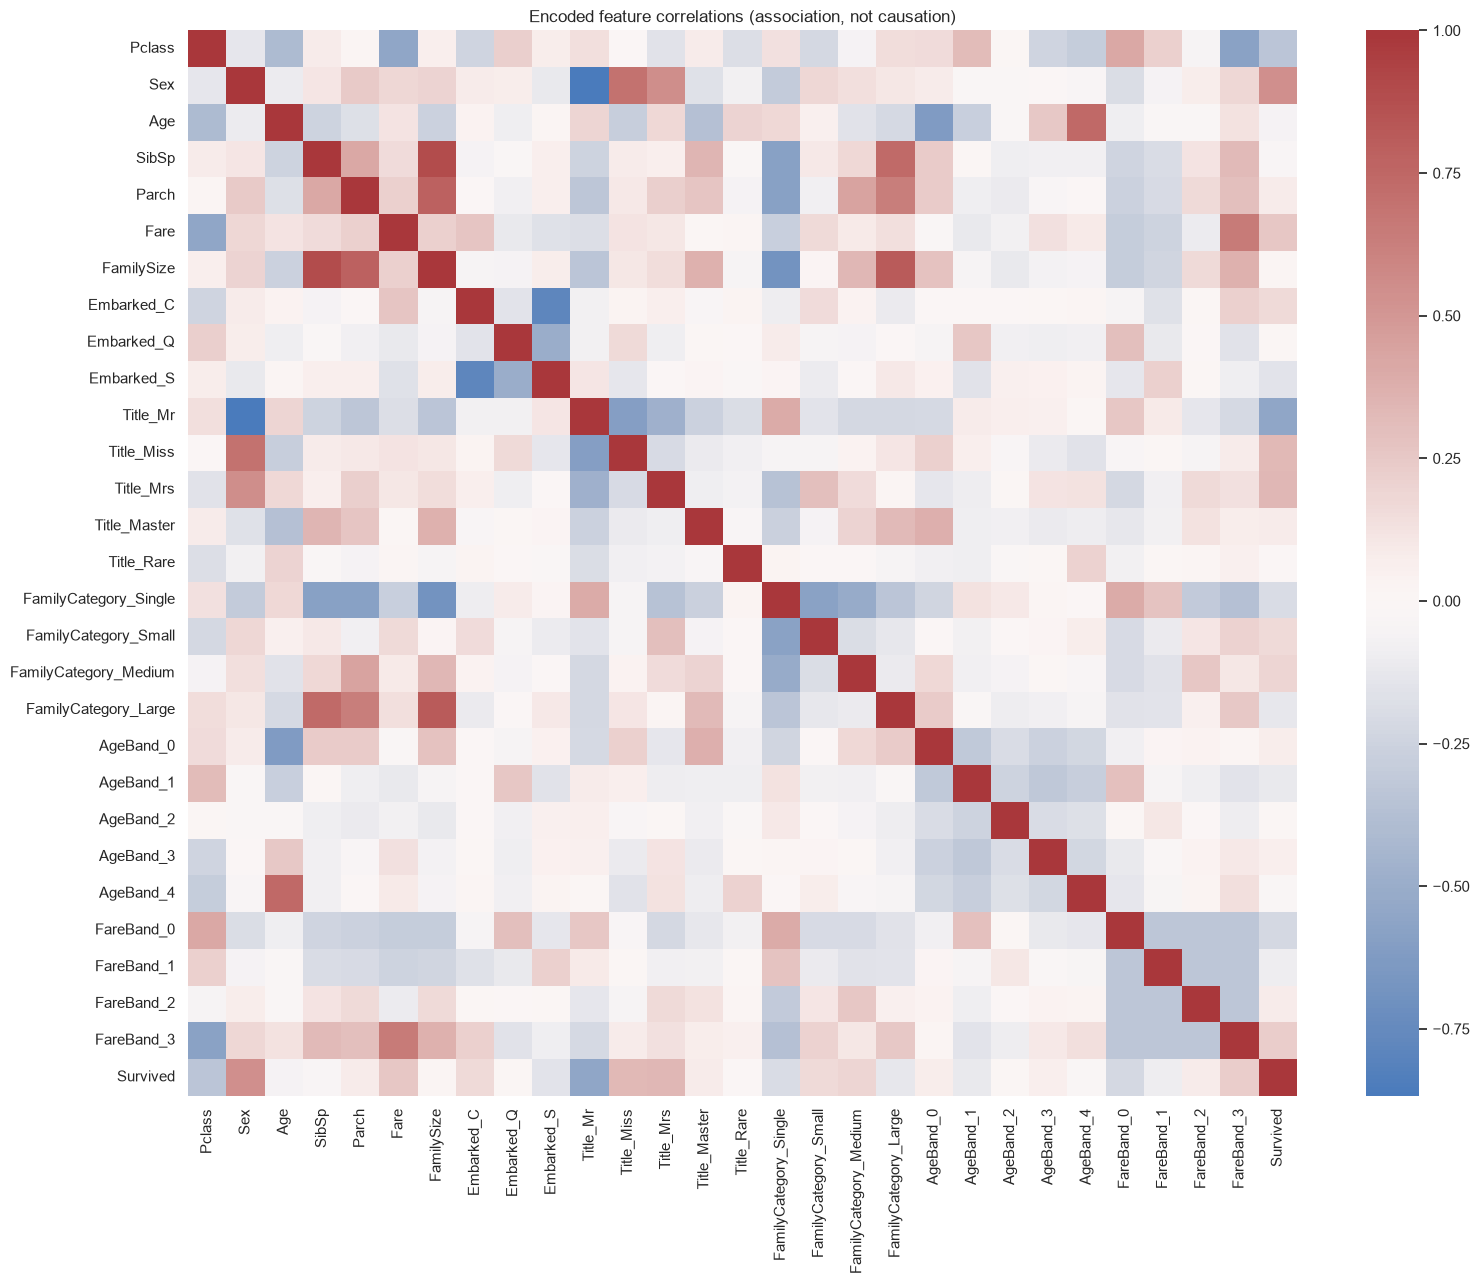

In [6]:
corr_data = pd.concat([X_full, y_full.rename('Survived')], axis=1)
fig, ax = plt.subplots(figsize=(16,13)); sns.heatmap(corr_data.corr(numeric_only=True), cmap='vlag', center=0, ax=ax); ax.set_title('Encoded feature correlations (association, not causation)')
fig.tight_layout(); fig.savefig(FIGURE_DIR / '07_encoded_correlation_heatmap.png', dpi=150); plt.show()

## Shared split, validation and artifact export

The one shared hold-out uses `test_size=0.20`, `stratify=y`, and seed 42. The shared CV contract is `StratifiedKFold(10, shuffle=True, random_state=42)`, with accuracy for selection and precision/recall/F1/ROC-AUC/confusion matrix for hold-out reporting. Scaling is deliberately absent from exported data; linear/SVM models must scale inside their own pipelines.

In [7]:
X_train, X_valid, y_train, y_valid = train_test_split(X_full, y_full, test_size=.20, stratify=y_full, random_state=RANDOM_STATE)
for name, frame in [('X_full',X_full),('X_test',X_test),('X_train',X_train),('X_valid',X_valid)]:
    assert frame.columns.tolist() == X_full.columns.tolist(), f'{name}: schema mismatch'
    assert not frame.isna().any().any(), f'{name}: NaN found'
    assert np.isfinite(frame.to_numpy(dtype=float)).all(), f'{name}: infinity found'
    assert not frame.select_dtypes(include=['object']).columns.any(), f'{name}: object feature found'
assert 'PassengerId' not in X_full.columns
split_balance = pd.DataFrame({'full': y_full.value_counts(normalize=True).sort_index(), 'train': y_train.value_counts(normalize=True).sort_index(), 'valid': y_valid.value_counts(normalize=True).sort_index()})
display(split_balance)
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
logreg = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
logreg_cv = cross_val_score(logreg, X_train, y_train, cv=CV, scoring='accuracy')
logreg.fit(X_train, y_train)
def metrics(model, X, y):
    pred = model.predict(X); score = model.predict_proba(X)[:,1] if hasattr(model, 'predict_proba') else pred
    return {'accuracy': accuracy_score(y,pred), 'precision': precision_score(y,pred,zero_division=0), 'recall': recall_score(y,pred,zero_division=0), 'f1': f1_score(y,pred,zero_division=0), 'roc_auc': roc_auc_score(y,score)}
baseline_metrics = {'dummy_most_frequent': metrics(dummy,X_valid,y_valid), 'logistic_regression': {**metrics(logreg,X_valid,y_valid), 'cv_accuracy_mean': float(logreg_cv.mean()), 'cv_accuracy_std': float(logreg_cv.std())}}
feature_rules = {'PassengerId':'kept separately; excluded from features', 'Embarked':f'train mode={embarked_mode}; train categories and one-hot', 'Fare':f'train median={fare_median}; raw plus quantile band', 'Age':f'train Sex×Pclass medians with global fallback={global_age_median}; raw plus quantile band', 'Title':'extract from Name; normalize Mlle/Ms/Mme; uncommon titles -> Rare; one-hot', 'FamilySize':'SibSp + Parch + 1', 'FamilyCategory':'Single=1, Small=2, Medium=3–4, Large>=5; one-hot', 'dropped':['Name','Ticket','Cabin'], 'scaling':'none in shared artifacts'}
manifest = {'features': X_full.columns.tolist(), 'dtypes': {c:str(t) for c,t in X_full.dtypes.items()}, 'target':'Survived', 'random_state':RANDOM_STATE, 'split':{'method':'train_test_split','test_size':.20,'stratify':'Survived','random_state':RANDOM_STATE}, 'cv':{'method':'StratifiedKFold','n_splits':10,'shuffle':True,'random_state':RANDOM_STATE,'primary_metric':'accuracy','additional_metrics':['precision','recall','f1','roc_auc','confusion_matrix']}, 'feature_engineering':feature_rules, 'learned_train_statistics':{'embarked_mode':embarked_mode,'fare_median':fare_median,'global_age_median':global_age_median,'age_group_medians':{f'{k[0]}|{k[1]}':float(v) for k,v in age_group_medians.items()},'age_band_edges':['-Infinity',*age_edges[1:-1].tolist(),'Infinity'],'fare_band_edges':['-Infinity',*fare_edges[1:-1].tolist(),'Infinity']}, 'library_versions':versions}
csv_artifacts = {'X_train.csv':X_train, 'X_valid.csv':X_valid, 'y_train.csv':y_train.rename('Survived').to_frame(), 'y_valid.csv':y_valid.rename('Survived').to_frame(), 'X_full.csv':X_full, 'y_full.csv':y_full.rename('Survived').to_frame(), 'X_test.csv':X_test, 'test_passenger_id.csv':test_passenger_id}
for filename, frame in csv_artifacts.items(): frame.to_csv(ARTIFACT_DIR / filename, index=False)
(ARTIFACT_DIR / 'feature_manifest.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
(ARTIFACT_DIR / 'baseline_metrics.json').write_text(json.dumps(baseline_metrics, indent=2), encoding='utf-8')
print('Final shapes:', {'X_train':X_train.shape,'X_valid':X_valid.shape,'X_full':X_full.shape,'X_test':X_test.shape})
print('Features:', X_full.columns.tolist()); print(json.dumps(baseline_metrics, indent=2))

,full,train,valid
Survived,,,
0,0.616162,0.616573,0.614525
1,0.383838,0.383427,0.385475


Final shapes: {'X_train': (712, 28), 'X_valid': (179, 28), 'X_full': (891, 28), 'X_test': (418, 28)}
Features: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Mr', 'Title_Miss', 'Title_Mrs', 'Title_Master', 'Title_Rare', 'FamilyCategory_Single', 'FamilyCategory_Small', 'FamilyCategory_Medium', 'FamilyCategory_Large', 'AgeBand_0', 'AgeBand_1', 'AgeBand_2', 'AgeBand_3', 'AgeBand_4', 'FareBand_0', 'FareBand_1', 'FareBand_2', 'FareBand_3']
{
  "dummy_most_frequent": {
    "accuracy": 0.6145251396648045,
    "precision": 0.0,
    "recall": 0.0,
    "f1": 0.0,
    "roc_auc": 0.5
  },
  "logistic_regression": {
    "accuracy": 0.8324022346368715,
    "precision": 0.8095238095238095,
    "recall": 0.7391304347826086,
    "f1": 0.7727272727272727,
    "roc_auc": 0.8681159420289856,
    "cv_accuracy_mean": 0.8215962441314554,
    "cv_accuracy_std": 0.0442163670243864
  }
}


## Independent reload check and model notebook scaffolds

This final check reads every exported file from disk, verifies schema and row counts, and only then creates the four model notebooks. Each scaffold consumes shared artifacts rather than repeating preprocessing.

In [8]:
reloaded = {name: pd.read_csv(ARTIFACT_DIR / name) for name in csv_artifacts}
reloaded_manifest = json.loads((ARTIFACT_DIR / 'feature_manifest.json').read_text(encoding='utf-8'))
reloaded_metrics = json.loads((ARTIFACT_DIR / 'baseline_metrics.json').read_text(encoding='utf-8'))
for name in ['X_train.csv','X_valid.csv','X_full.csv','X_test.csv']:
    assert reloaded[name].columns.tolist() == reloaded_manifest['features']
assert len(reloaded['X_full.csv']) == len(reloaded['y_full.csv']) == len(train_raw)
assert len(reloaded['X_test.csv']) == len(reloaded['test_passenger_id.csv']) == len(test_raw)
assert reloaded_metrics == baseline_metrics
print('Independent artifact reload: PASS')

import nbformat as nbf
models = [
 ('logistic_regression','01_logistic_regression.ipynb','Logistic Regression'),
 ('extra_trees','02_extra_trees.ipynb','Extra Trees'),
 ('svm','03_svm.ipynb','Support Vector Machine'),
 ('decision_tree','04_decision_tree.ipynb','Decision Tree'),
]
headings = ['Setup','Load shared artifacts','Baseline','Cross-validation','Hyperparameter tuning','Validation evaluation','Learning curve','Refit full data','Test prediction','Export artifacts','Conclusion']
for folder, filename, title in models:
    path = ROOT / 'members' / folder / filename; path.parent.mkdir(parents=True, exist_ok=True)
    nb = nbf.v4.new_notebook()
    nb.cells = [nbf.v4.new_markdown_cell(f'# {title}\n\nShared work already completed: raw-data audit, EDA, train-only imputation and band thresholds, feature engineering/encoding, one stratified hold-out split, artifact validation, and the 10-fold CV contract. This notebook must not preprocess raw Titanic data again.')]
    for heading in headings:
        nb.cells.append(nbf.v4.new_markdown_cell(f'## {heading}'))
        if heading == 'Setup': nb.cells.append(nbf.v4.new_code_cell("from pathlib import Path\nimport json, pandas as pd\nRANDOM_STATE = 42\nROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'PROJECT_PLAN.md').exists())\nARTIFACT_DIR = ROOT / 'artifacts' / 'common'"))
        if heading == 'Load shared artifacts': nb.cells.append(nbf.v4.new_code_cell("X_train = pd.read_csv(ARTIFACT_DIR / 'X_train.csv')\nX_valid = pd.read_csv(ARTIFACT_DIR / 'X_valid.csv')\ny_train = pd.read_csv(ARTIFACT_DIR / 'y_train.csv').squeeze('columns')\ny_valid = pd.read_csv(ARTIFACT_DIR / 'y_valid.csv').squeeze('columns')\nX_full = pd.read_csv(ARTIFACT_DIR / 'X_full.csv')\ny_full = pd.read_csv(ARTIFACT_DIR / 'y_full.csv').squeeze('columns')\nX_test = pd.read_csv(ARTIFACT_DIR / 'X_test.csv')\ntest_passenger_id = pd.read_csv(ARTIFACT_DIR / 'test_passenger_id.csv')\nmanifest = json.loads((ARTIFACT_DIR / 'feature_manifest.json').read_text(encoding='utf-8'))\nassert X_train.columns.tolist() == manifest['features'] == X_test.columns.tolist()\nprint(X_train.shape, X_valid.shape, X_test.shape)"))
    nb.metadata.kernelspec = {'display_name':'Python 3','language':'python','name':'python3'}
    nb.metadata.language_info = {'name':'python','version':platform.python_version()}
    nbf.write(nb, path)
print('Created model notebook scaffolds:', [str(ROOT / 'members' / f / n) for f,n,_ in models])

Independent artifact reload: PASS


Created model notebook scaffolds: ['C:\\Users\\MSI\\Desktop\\MyProducts\\My Project\\AIL\\Mini_Capstone\\members\\logistic_regression\\01_logistic_regression.ipynb', 'C:\\Users\\MSI\\Desktop\\MyProducts\\My Project\\AIL\\Mini_Capstone\\members\\extra_trees\\02_extra_trees.ipynb', 'C:\\Users\\MSI\\Desktop\\MyProducts\\My Project\\AIL\\Mini_Capstone\\members\\svm\\03_svm.ipynb', 'C:\\Users\\MSI\\Desktop\\MyProducts\\My Project\\AIL\\Mini_Capstone\\members\\decision_tree\\04_decision_tree.ipynb']


## Conclusion

The shared contract provides leakage-aware train-derived preprocessing, reproducible split/CV settings, fully numeric aligned features, baseline health checks, and independently reloadable artifacts. Sex, class, age, fare, title, and family structure show useful associations; model notebooks should validate their incremental value rather than interpret these associations causally.